# ``meshlab`` - Tutorial 4

**Airfoil mesh generation and export**


## 1. Import packages
---


In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, smooth_normals, advance_front,
)
from meshlab.utils import plot_mesh
from meshlab.export import export_mesh

## 2. Geometries definition
---


NACA 2412 airfoil


In [2]:
# Input directory
tutorial_dir = Path.cwd() if Path.cwd().name == "tutorials" else Path.cwd() / "tutorials"

# Load airfoil coordinates
points = np.loadtxt(tutorial_dir / "data/NACA-2412.dat")

# Close the counter-clockwise curve
points = np.vstack((points, points[0]))

# Define contour
surface = Contour("airfoil", [Curve("wall", points)])

## 3. Creating mesh surfaces
---


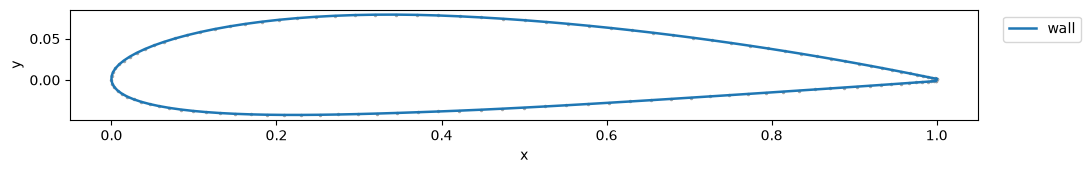

In [3]:
# 2D mesh definition
mesh = Mesh(dim=2, vertices_capacity=5000, cells_capacity=5000)

# Insert contour
insert_contour(mesh, surface)

figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.set_size_inches(11, 6)
figure.tight_layout()

plt.show()

## 4. Initialize front
---


In [ ]:
# Layer parameters
num_layers = 10
height = 0.0002
growth_rate = 1.10
smooth_steps = 5
relaxation = 1.0

# Front definition
front = Front("airfoil_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

## 5. Growing boundary layers
---


In [5]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="central")
    for _ in range(smooth_steps):
        normals, _ = smooth_normals(mesh, front, normals, relaxation)

    advance_front(mesh, front, normals, h)
    h *= growth_rate

# Recompute normals at the current front vertices
normals = compute_normals(mesh, front, method="central")

Visualize mesh


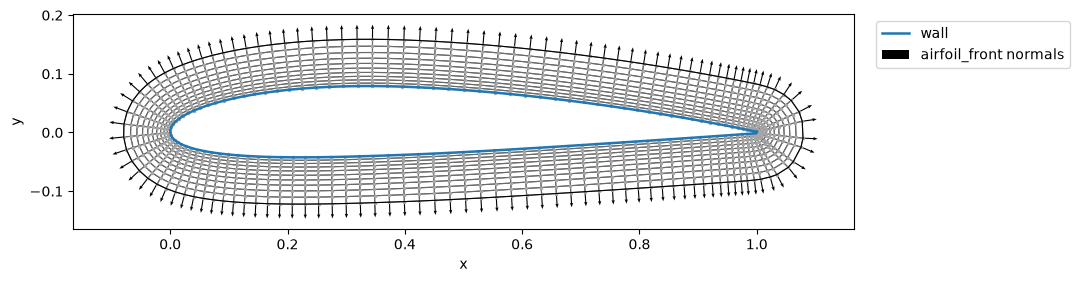

In [6]:
figure, ax = plot_mesh(mesh, normals=[(front, normals)], normal_scale=0.025, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.set_size_inches(11, 6)
figure.tight_layout()

plt.show()

## 6. Circular domain
---


In [7]:
# Geometric parameters
farfield_radius = 10.0
farfield_points = 80

# External contour in a clockwise direction
angles = np.linspace(0.0, -2.0 * np.pi, farfield_points, endpoint=False)
points = farfield_radius * np.column_stack((np.cos(angles), np.sin(angles)))

# Close curve
points = np.vstack((points, points[0]))

# Define and insert contour
farfield = Contour("outer_domain", [Curve("freestream", points)])
insert_contour(mesh, farfield)

## 7. Generate and export the Gmsh mesh
---


In [ ]:
# Export parameters
thickness = 0.1
mesh_size = 0.5
show_gmsh = False                                   # True opens the interactive Gmsh window
filename = tutorial_dir / "results/NACA-2412.msh"
filename.parent.mkdir(parents=True, exist_ok=True)

In [9]:
# Preserve layers, triangulate the remaining region and extrude one cell in z
export_mesh(
    mesh,
    fronts=[front],
    filename=filename,
    mode="planar",
    thickness=thickness,
    mesh_size=mesh_size,
    show=show_gmsh,
)

print(filename)

/home/user/Documentos/GitHub/meshlab/tutorials/results/NACA-2412.msh


### Convert to OpenFOAM
---
- Run in a terminal using a prepared OpenFOAM case:
- Set writePrecision to 16 in system/controlDict before conversion.
- gmshToFoam /path/to/tutorials/results/NACA-2412.msh
- Set frontAndBack to empty in constant/polyMesh/boundary and the field files.
- checkMesh -allTopology -allGeometry